<a href="https://colab.research.google.com/github/RonsJose/ml-project-colab/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Machine Learning project**

*Rons Jose*

*G00464215*

In this project I'm going over a dataset collected by our class on the Galway City campus and analysing it.

##**Importing libraries**



>Mounting the drive in which the data is located and importing all the required libraries.



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
from sklearn.preprocessing import scale
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [5]:
import seaborn as sns

### Reading the data into a pandas dataset.

*Skipping the first 4 rows because they don't contain anything.*

In [6]:
df = pd.read_csv(
    '/content/drive/MyDrive/Machine Learning Project/CampusWalkDataset_TemplateIDs.csv',
    skiprows=4
)

*Using the pandas display function which puts the data into a table format making it easy to read. Adding additional context to allow us to view as many rows as desired.*

In [7]:
pd.set_option('display.max_columns', None)
with pd.option_context('display.max_rows', 20):
    display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,NaN,NaN,NaN,NaN
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,NaN,NaN,NaN,NaN
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,NaN,NaN,NaN,NaN
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,NaN,NaN,NaN,NaN
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **Cleaning**

### **Removing blank cells**

*  *Using the dropna function to remove the rows with less than 5 valid pieces of data.*

* *Deleting 4 specific coloumns from the list that are empty using the drop function and indexing.*

In [8]:
df.dropna(thresh=5,inplace=True)
df.drop(["Unnamed: 23","Unnamed: 24","Unnamed: 25","Unnamed: 26"], axis=1,inplace=True)
with pd.option_context('display.max_rows', 20):
  display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,R26_027,23/09/2026,L04 PathFrontiHub,Windy,16C,Quiet,Low,Traffic,Human voices,Trees,Wind,0.0,2.0,Many,Some,Some,NaN,Positive wellbeing,Easy,Mostly calm,Much more connected,Plants,NaN
134,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10,Quiet,Low,Other,Human voices,Wind,Trees,0.0,0.0,One or two,NaN,NaN,NaN,Neutral,Easy,Mostly calm,Less connected,Trees,NaN
135,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10,Moderate,Low,Traffic,Other,Wind,Wind,3.0,1.0,Many,Many,NaN,Some,Positive wellbeing,Easy,Very calm,Much more connected,plants,NaN
136,R26_028,07/10/2026,L01 MainEntrance,Partly cloudy,15,Moderate,Moderate,Traffic,Construction,Other birds,Trees,0.0,0.0,Many,Some,NaN,Many,Positive wellbeing,Neutral,Neutral,No change,grass,NaN


### **Cleaning columns**

* *Cleaning the temperature column because it has the "C" for celcius in a few piece of data.*

* *Changing the formatting of both weather and foot_traffic column to only use lowercase letters.*

* *Removing whitespace from 3 different columns.*

* *Replacing the text in nature_connection_experience_rating column to match the rest of the data.*



In [9]:
df['temperature_c']= df['temperature_c'].str.replace('C', '', case=False)

df['weather']=df['weather'].str.lower()
df['foot_traffic']=df['foot_traffic'].str.lower()

df['moss_or_lichen_presence']=df['moss_or_lichen_presence'].str.strip()
df['ornnamental_or_planted_plant_presence']=df['ornnamental_or_planted_plant_presence'].str.strip()
df['native_or_wild_plant_presence']=df['native_or_wild_plant_presence'].str.strip()

df['nature_connection_experience_rating']= df['nature_connection_experience_rating'].str.replace('same', 'No change', case=False)

## **Encoding**


### **Label Encoding**

* *Using python dictionaries make a key for each column that orders the values in the data accurately.*

* *Then we check to see if there are any NaN values in the columns if there are, then replace it with "none".*

* *Using the map() function and the dictionaries created early, it maps the strings to the corresponding numbers and make a new column with the encoded value.*



> *I'm label encoding because machine learning algorithms are not designed for words to be used, they are designed for numbers. And doing it this way allows for me to be able to use the order of magnitude of the words into numbers and map them accordingly.*



In [10]:
sound_mapping = {
    'Quiet' :0,
    'Moderate':1,
    'Loud': 2
}

foot_traffic_mapping = {
    'low': 0,
    'moderate': 1,
    'high': 2
}

wellbeing_rating_mapping = {
    'Very low wellbeing': 0,
    'Low wellbeing': 1,
    'Neutral': 2,
    'Positive wellbeing': 3,
    'Very positive wellbeing': 4
}

ease_rating_mapping = {
    'Vey easy': 0,
    'Easy': 1,
    'Neutral': 2,
    'Slighly uneasy': 3,
    'Very uneasy': 4
}

stress_rating_mapping = {
    'Very calm': 0,
    'Mostly calm': 1,
    'Neutral': 2,
    'Stressful': 3,
    'Very stressful' :4
}

nature_connection_experience_rating_mapping = {
    'Much more connected': 0,
    'A little more connected': 1,
    'No change': 2,
    'Less connected': 3
}

trees_presence_mapping = {
    'Many': 0,
    'One or two': 1,
    'none': 2
}

native_or_wild_plant_presence_mapping = {
    'Many': 0,
    'Some': 1,
    'none': 2
}

ornnamental_or_planted_plant_presence_mapping = {
    'Many': 0,
    'Some': 1,
    'none': 2
}

moss_or_lichen_presence_mapping = {
    'Many': 0,
    'Some': 1,
    'none': 2
}

df['trees_presence'] = df['trees_presence'].fillna('none').astype(str)
df['native_or_wild_plant_presence'] = df['native_or_wild_plant_presence'].fillna('none').astype(str)
df['ornnamental_or_planted_plant_presence'] = df['ornnamental_or_planted_plant_presence'].fillna('none').astype(str)
df['moss_or_lichen_presence'] = df['moss_or_lichen_presence'].fillna('none').astype(str)


df['sound_encoded'] = df['sound level'].map(sound_mapping)

df['foot_traffic_encoded'] = df['foot_traffic'].map(foot_traffic_mapping)

df['trees_presence_encoded']= df['trees_presence'].map(trees_presence_mapping)

df['native_or_wild_plant_presence_encoded']= df['native_or_wild_plant_presence'].map(native_or_wild_plant_presence_mapping)

df['ornnamental_or_planted_plant_presence_encoded']= df['ornnamental_or_planted_plant_presence'].map(ornnamental_or_planted_plant_presence_mapping)

df['moss_or_lichen_presence_encoded']= df['moss_or_lichen_presence'].map(moss_or_lichen_presence_mapping)

df['wellbeing_rating_encoded'] = df['wellbeing_rating'].map(wellbeing_rating_mapping)

df['ease_rating_encoded'] = df['ease_rating'].map(ease_rating_mapping)

df['stress_rating_encoded'] = df['stress_rating'].map(stress_rating_mapping)

df['nature_connection_experience_rating_encoded'] = df['nature_connection_experience_rating'].map(nature_connection_experience_rating_mapping)

with pd.option_context('display.max_rows', 20):
    display(df)



,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,sound_encoded,foot_traffic_encoded,trees_presence_encoded,native_or_wild_plant_presence_encoded,ornnamental_or_planted_plant_presence_encoded,moss_or_lichen_presence_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_experience_rating_encoded
0,R26_001,22/09/2026,L01 MainEntrance,partly cloudy,16,Quiet,low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,0,0,0,1,1,1,3,2,3,3
1,R26_001,22/09/2026,L02 LibraryGreen,sunny,16,Moderate,low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,none,Some,none,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,1,0,0,2,1,2,3,2,2,1
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,partly cloudy,16,Quiet,low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,none,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,0,0,0,2,0,1,3,1,1,2
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,partly cloudy,16,Moderate,low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,none,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,1,0,1,1,2,1,3,2,2,0
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,sunny,16,Moderate,low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,none,Some,none,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,1,0,1,2,1,2,3,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,R26_027,23/09/2026,L04 PathFrontiHub,windy,16,Quiet,low,Traffic,Human voices,Trees,Wind,0.0,2.0,Many,Some,Some,none,Positive wellbeing,Easy,Mostly calm,Much more connected,Plants,NaN,0,0,0,1,1,2,3,1,1,0
134,R26_028,07/10/2026,L10 OtherOffCampus,windy,10,Quiet,low,Other,Human voices,Wind,Trees,0.0,0.0,One or two,none,none,none,Neutral,Easy,Mostly calm,Less connected,Trees,NaN,0,0,1,2,2,2,2,1,1,3
135,R26_028,07/10/2026,L10 OtherOffCampus,windy,10,Moderate,low,Traffic,Other,Wind,Wind,3.0,1.0,Many,Many,none,Some,Positive wellbeing,Easy,Very calm,Much more connected,plants,NaN,1,0,0,0,2,1,3,1,0,0
136,R26_028,07/10/2026,L01 MainEntrance,partly cloudy,15,Moderate,moderate,Traffic,Construction,Other birds,Trees,0.0,0.0,Many,Some,none,Many,Positive wellbeing,Neutral,Neutral,No change,grass,NaN,1,1,0,1,2,0,3,2,2,2


### **One Hot Encoding**

* *In a list contain the names of all the columns to be encoded.*
* *Check to ensure that there aren't any NaN values in the columns*
* *Use the pandas get_dummies() function with the arguments being the dataframe and the columns to be encoded.*



> *Using one hot encoding because machine learning models don't understand text, only numbers. But some data like these can't be label encoded because they're not ordered. If it was label encoded the model would assume that if "rain = 1" and "cloud = 3" that cloud is of a greater value which it isn't. One hot encoding solves this by making true and false column for every category.*



> *Two columns [most_notable_nature_element] & [other_notes] were not one hot encoded because I've decided that it is not worth it to use them in the analysis as they add too many columns when encoded and  the does not have relationships with other data pieces*




In [11]:
cols_to_one_hot = [
    'weather',
    'location',
    'primary_sound_type_urban',
    'other_sound_type_urban',
    'primary_sound_type_nature',
    'other_sound_type_nature'
]

for col in cols_to_one_hot:
    df[col] = df[col].fillna('Other').astype(str).str.lower().str.strip()

# By passing only the selected columns to pd.get_dummies,
# df_encoded will only contain the resulting one-hot encoded features.
df_encoded = pd.get_dummies(df[cols_to_one_hot])

print(f"Original DataFrame shape: {df.shape}")
print(f"One-hot Encoded-only DataFrame shape: {df_encoded.shape}")
display(df_encoded.head())

Original DataFrame shape: (135, 33)
One-hot Encoded-only DataFrame shape: (135, 35)


,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,location_l01 mainentrance,location_l02 librarygreen,location_l03 lowersidepathihub,location_l04 pathfrontihub,location_l05 greenfrontsportscentre,location_l06 hedgingbehindsportscentre,location_l07 carparknearsportscentre,location_l08 accessroadnearsportscentre,location_l10 otheroffcampus,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic,primary_sound_type_nature_insects,primary_sound_type_nature_other,primary_sound_type_nature_other birds,primary_sound_type_nature_seagulls,primary_sound_type_nature_trees,primary_sound_type_nature_wind,other_sound_type_nature_insects,other_sound_type_nature_other,other_sound_type_nature_other birds,other_sound_type_nature_seagulls,other_sound_type_nature_trees,other_sound_type_nature_wind
0,False,True,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,True,False
1,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False
2,False,True,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,True,False,False,False
3,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False
4,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,False


## **Scaling**

* *In a list name all the columns that need to be scaled*
* *Using the scale() function from sklearn, scale the selected columns from the dataframe.*



> *The data is scaled so that features with bigger numbers are not favoured over features with smaller numbers during calculations due to the model running based on the euclidean distance formula. Forcing all the numbers from -1 to 1 evens the playing field, forcing the model to judge the variables based on their actual value not just the raw size.*



In [12]:

# Select the columns correctly by placing all column names in a single list
columns_to_scale = [
    'temperature_c', 'insects_count', 'birds_count', 'sound_encoded',
    'foot_traffic_encoded', 'trees_presence_encoded', 'native_or_wild_plant_presence_encoded',
    'ornnamental_or_planted_plant_presence_encoded', 'moss_or_lichen_presence_encoded',
    'wellbeing_rating_encoded', 'ease_rating_encoded', 'stress_rating_encoded',
    'nature_connection_experience_rating_encoded'
]
df_filled = df[columns_to_scale]

# Run the scaling
df_scaled = scale(df_filled)

# Display the scaled values in a nice DataFrame
df_scaled_display = pd.DataFrame(df_scaled, columns=columns_to_scale)
with pd.option_context('display.max_rows', 20):
    display(df_scaled_display)


,temperature_c,insects_count,birds_count,sound_encoded,foot_traffic_encoded,trees_presence_encoded,native_or_wild_plant_presence_encoded,ornnamental_or_planted_plant_presence_encoded,moss_or_lichen_presence_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_experience_rating_encoded
0,-0.483562,-0.537246,-0.357106,-1.022948,-0.587805,-0.546431,0.406017,-0.009939,-0.020578,0.374970,0.704598,2.104730,1.489025
1,-0.483562,-0.537246,0.002665,0.446180,-0.587805,-0.546431,2.066998,-0.009939,1.368446,0.374970,0.704598,0.944981,-0.425436
2,-0.483562,1.428288,6.478545,-1.022948,-0.587805,-0.546431,2.066998,-1.351646,-0.020578,0.374970,-0.388744,-0.214768,0.531795
3,-0.483562,-0.537246,0.002665,0.446180,-0.587805,1.345060,0.406017,1.331768,-0.020578,0.374970,0.704598,0.944981,-1.382666
4,-0.483562,-0.537246,-0.716877,0.446180,-0.587805,1.345060,2.066998,-0.009939,1.368446,0.374970,-0.388744,-0.214768,1.489025
...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,-0.483562,-0.537246,0.002665,-1.022948,-0.587805,-0.546431,0.406017,-0.009939,1.368446,0.374970,-0.388744,-0.214768,-1.382666
131,-4.959964,-0.537246,-0.716877,-1.022948,-0.587805,1.345060,2.066998,1.331768,1.368446,-0.830291,-0.388744,-0.214768,1.489025
132,-4.959964,0.052414,-0.357106,0.446180,-0.587805,-0.546431,-1.254963,1.331768,-0.020578,0.374970,-0.388744,-1.374518,-1.382666
133,-1.229629,-0.537246,-0.716877,0.446180,0.938228,-0.546431,0.406017,1.331768,-1.409602,0.374970,0.704598,0.944981,0.531795


## **Correlation**

* *Combine the two dataframes using the pandas concat() function*
* *Run the corr() function*
* *Use the figure() function from plt to setup the plot size*
* *Draw the heatmap with the preferred settings*
* *Use the show() function to display the plot*

> *Doing a correlation lets me looks at the relationship each feature has with another feature, this will help me pick out features that have strong relations with other features for the model.*



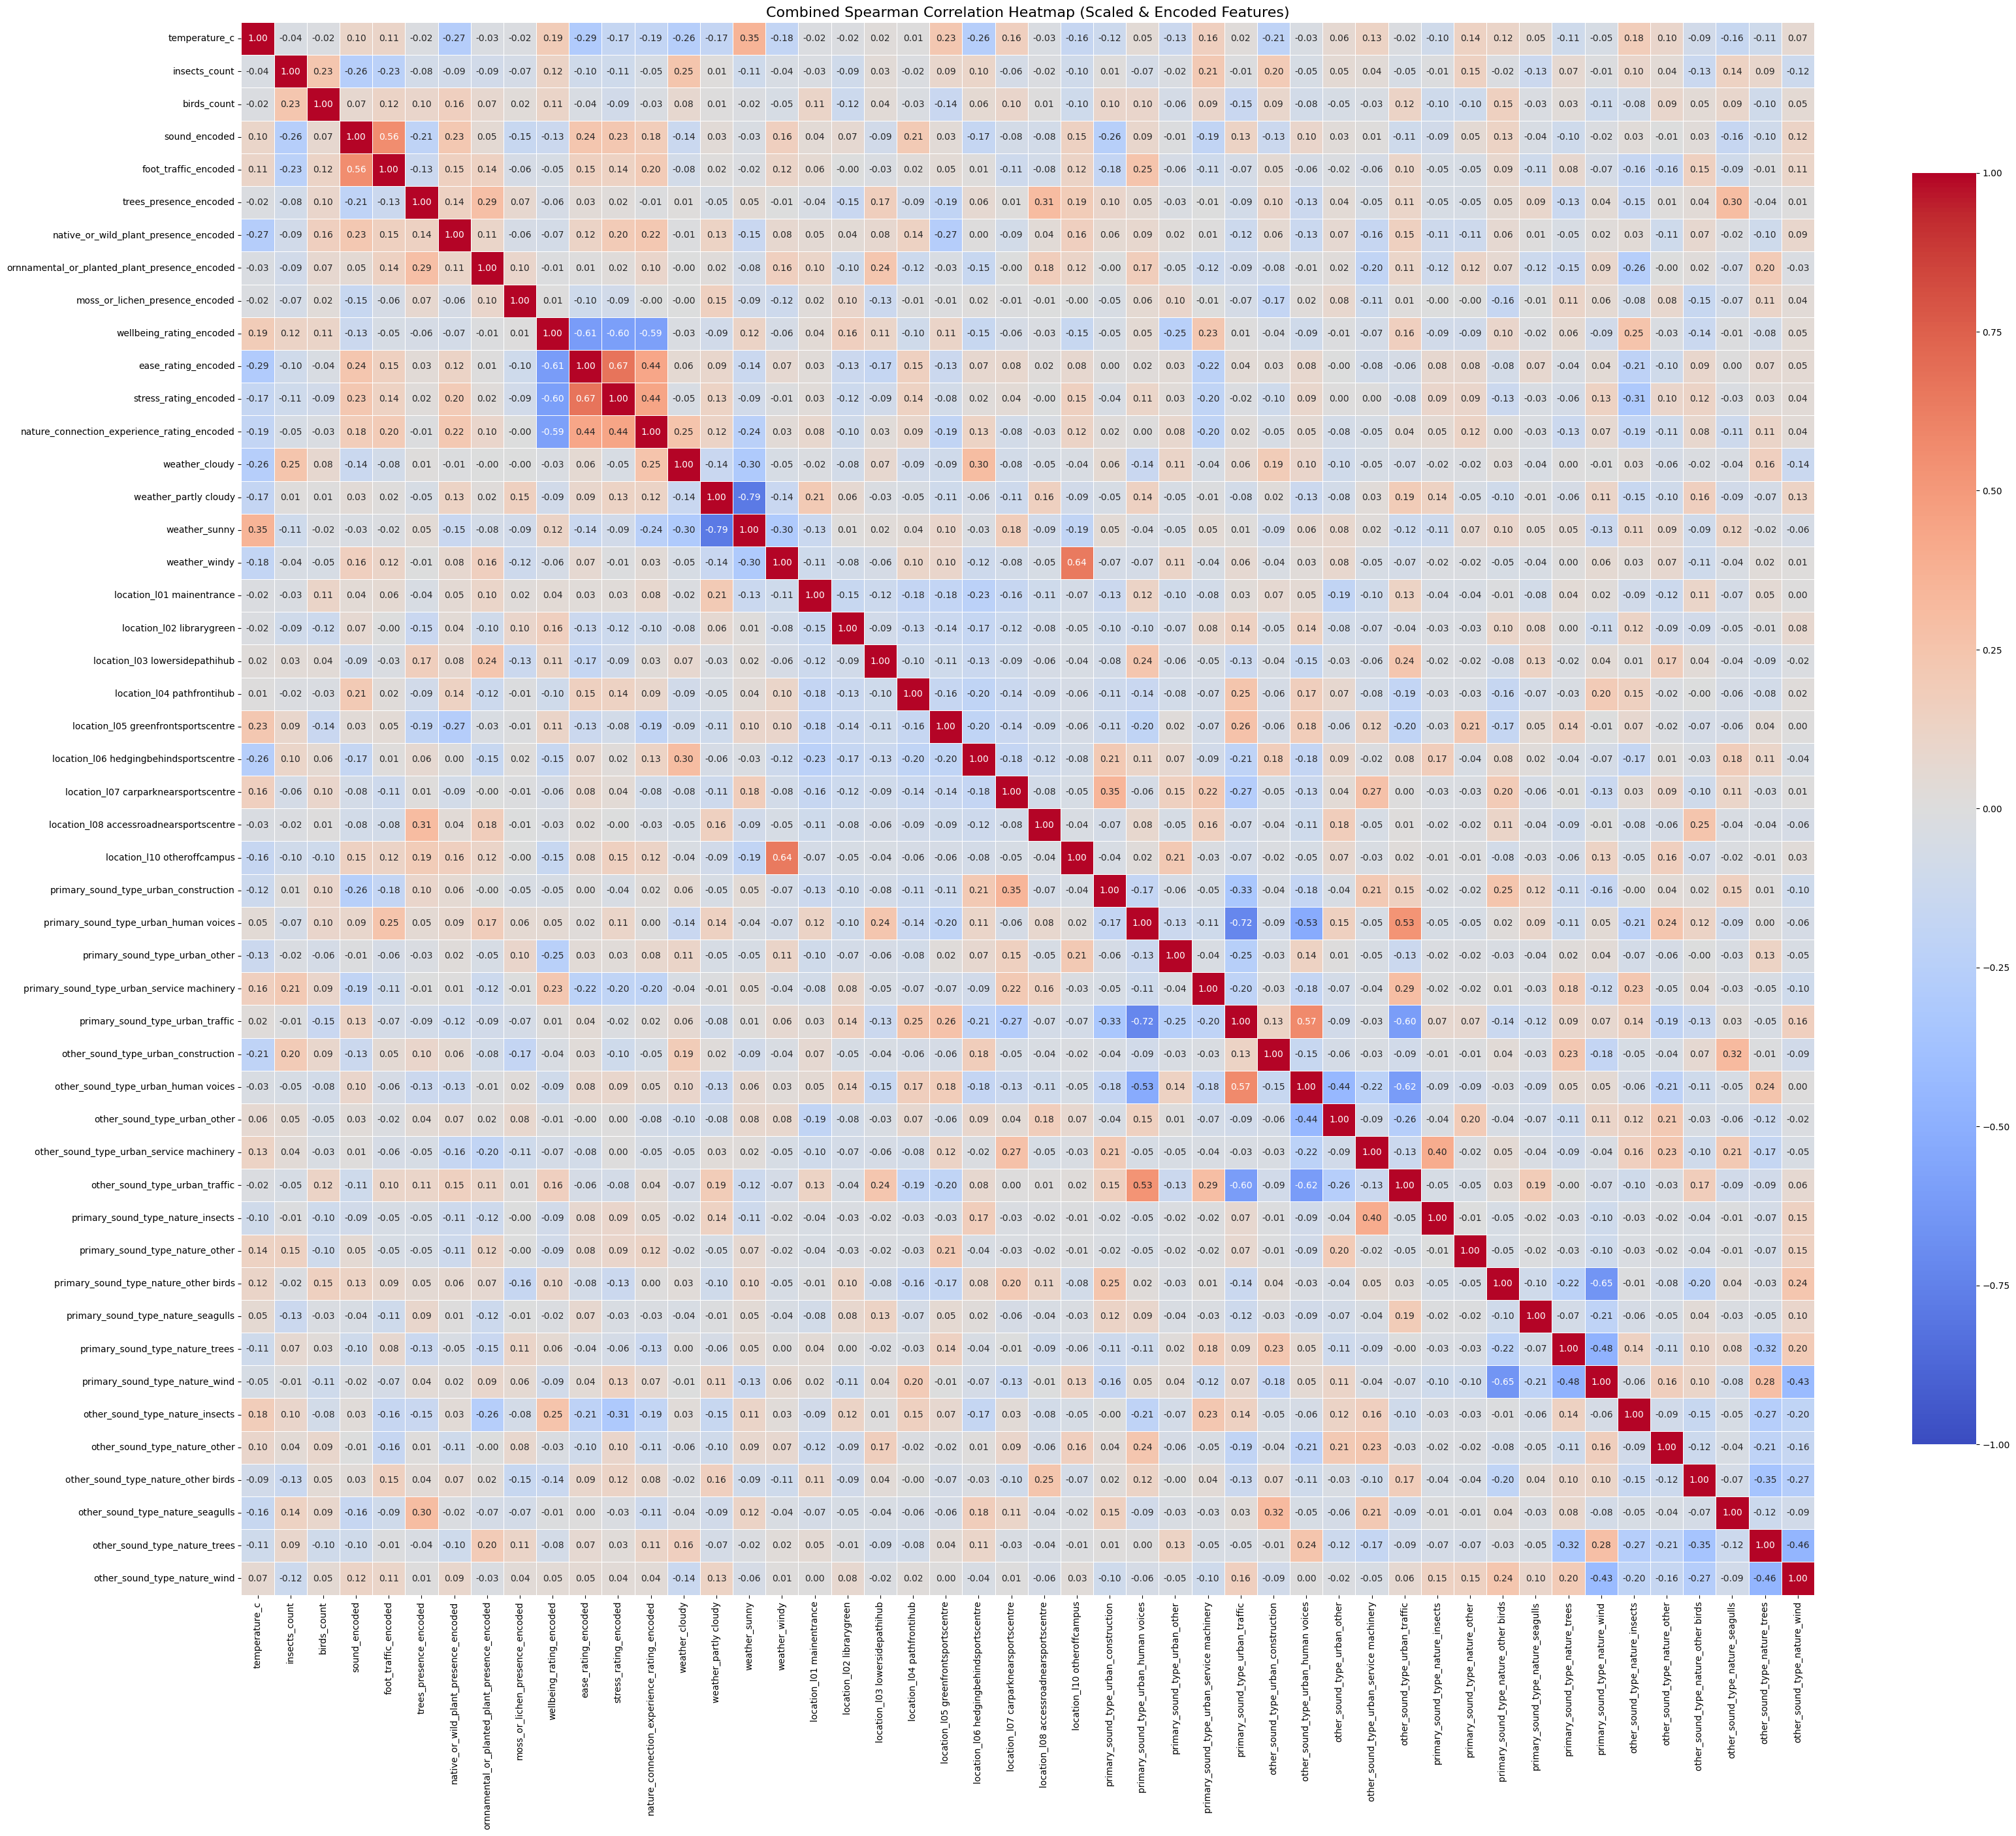

In [13]:
# 1. Combine the two DataFrames side-by-side (axis=1)
df_combined = pd.concat([df_scaled_display, df_encoded], axis=1)

# 2. Calculate the combined correlation matrix (ignoring non-numeric text columns)
corr_matrix = df_combined.corr(method='spearman')

# 3. Set up the matplotlib figure
plt.figure(figsize=(34, 28))

# 4. Draw the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title('Combined Spearman Correlation Heatmap (Scaled & Encoded Features)', fontsize=16)
plt.tight_layout()
plt.show()

### **Features to take**


*   Nature sound of birds & nature sound of wind
*   Traffic sounds & human voices
*  Foot traffic & sound level
*  Stress & ease
*  Nature connection & wellbeing
* Sunny weather & partly cloudy


## **Clusters**



> *I'm going to cluster the data to analyse how the selected features are grouped together according to the algorithm. And use PCA to turn the data 2D so that I can view it on a graph.*



### **Creating new dataframe with selected coloumns**

* *Make a list with the names of the columns that are to be clustered.*
* *There were NaN values in the combined dataframe so they were changed to a 0 value.*
* *New dataframe made to contain all the data to be clustered.*




In [14]:
cols_to_cluster = [
    'foot_traffic_encoded',
    'sound_encoded',
    'wellbeing_rating_encoded',
    'nature_connection_experience_rating_encoded',
    'ease_rating_encoded',
    'stress_rating_encoded',
    'weather_sunny',
    'weather_partly cloudy',
    'primary_sound_type_nature_wind',
    'primary_sound_type_nature_other birds'
]

for col in cols_to_cluster:
    # Fill missing values with numeric 0 and ensure they are numeric
    df_combined[col] = pd.to_numeric(df_combined[col].fillna(0))

df_cluster = df_combined[cols_to_cluster]


In [15]:
num_clusters = 5

kmeans = KMeans(
    init="random",
    n_clusters=num_clusters,
    n_init=9,
    random_state=0,
)

In [16]:
kmeans.fit(df_cluster)

KMeans(init='random', n_clusters=5, n_init=9, random_state=0)

In [17]:
labels = kmeans.labels_

In [18]:
score = silhouette_score(df_cluster, labels)

print(score)

0.1872929425864486


### **Table of different silhouette scores**

| Number of clusters    | Silhouette score |
| -------- | ------- |
| 2  |   0.237  |
| 3  |   0.239  |
| 4  |   0.1878  |
| 5  |   0.1872  |
| 6  |   0.184  |
| 7  |   0.170  |
| 8  |  0.174   |



> *Even though 3 clusters give the best silhouette score it is still within the category of being very close to another cluster, which doing 5 clusters also gives me. I prefer the position of the clusters and centroids when using 5.*




## **Principle component analysis**

*PCA is used to take mulitple dimensional data and convert it to a data with 2 dimensions. Because the data set that I've decided to cluster has more than 2 dimensions it won't be a human readable graph, and I want to be able to plot a graph with the clustered data. PCA does this by making a graph with the different features and then using the distance from the point it plots on the graph to the origin it calculates the position on first principle component axis, the data points on the second axis is found by drawing the line of PC 2 perpendicular to PC 1 while going through the origin. The same is done for the rest of the principle components, by going through the origin and perpendicular to the rest of the PC axis's*


In [19]:

pca = PCA(n_components=2)

data_projected = pca.fit_transform(
    df_cluster
    )
centroids_projected = pca.transform(
    kmeans.cluster_centers_
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [20]:
print(df_cluster.shape)
print(data_projected.shape)

(138, 10)
(138, 2)


### **Plotting the graph of clusters**

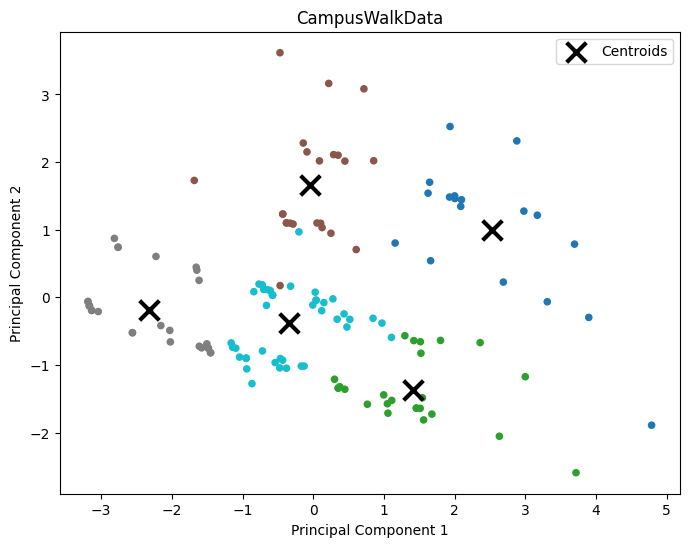

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    data_projected[:, 0],
    data_projected[:, 1],
    c=labels,
    cmap="tab10",
    s=20,
)

plt.scatter(
    centroids_projected[:, 0],
    centroids_projected[:, 1],
    marker="x",
    c="black",
    s=200,
    linewidths=3,
    label="Centroids",
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "CampusWalkData"
)

plt.legend()
plt.show()

### **Scree Plot of Principal Components**

Let's analyze how much of the variance in our clustered features is explained by each of the principal components.

> *I'm analyzing this because we only plot the graph with two of the principle components, PC1 & PC2. If these two did not take up most of the variance in the data, (currently it takes up 60% of total variance) the graph that is plotted using the two PC's(principle components) would be much more inaccurate. The fact that both of these PC's is what enables us to plot the graph in 2d.*



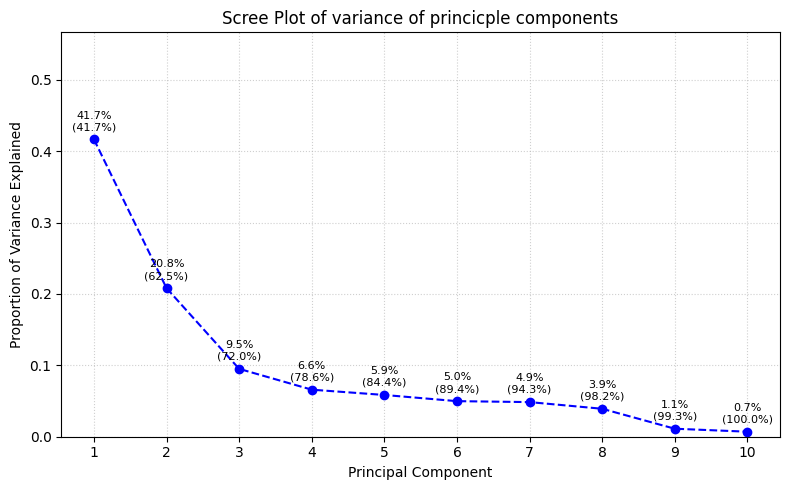

In [22]:
# Fit PCA to explain the entire variance to show the scree plot across all potential components
pca_full = PCA()
pca_full.fit(df_cluster.drop(columns=['cluster_label'], errors='ignore'))

# Calculate explained variance ratio
explained_variance = pca_full.explained_variance_ratio_

# Plot the scree plot
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o',
    linestyle='--',
    color='b'
)

plt.title('Scree Plot of variance of princicple components')
plt.xlabel('Principal Component')
plt.ylabel('Proportion of Variance Explained')
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(range(1, len(explained_variance) + 1))

# Display cumulative variance explained above each bar/point
cumulative_variance = np.cumsum(explained_variance)
for i, (val, cum) in enumerate(zip(explained_variance, cumulative_variance)):
    plt.text(i + 1, val + 0.01, f"{val*100:.1f}%\n({cum*100:.1f}%)", ha='center', va='bottom', fontsize=8)

plt.ylim(0, max(explained_variance) + 0.15)
plt.tight_layout()
plt.show()

### **PCA Feature Loadings (Feature Contribution to Components)**

To understand which features affect each principal component the most, we look at the PCA loadings (weights) for each feature on each principal component.

* *PC1 represents Internal State (Stress, Ease, Wellbeing, and Nature Connection).*

* *PC2 represents External Activity/Stimulation (Foot Traffic and Sound Levels).*
* *Weather conditions and specific nature sound types have minimal influence on both of these major components.*

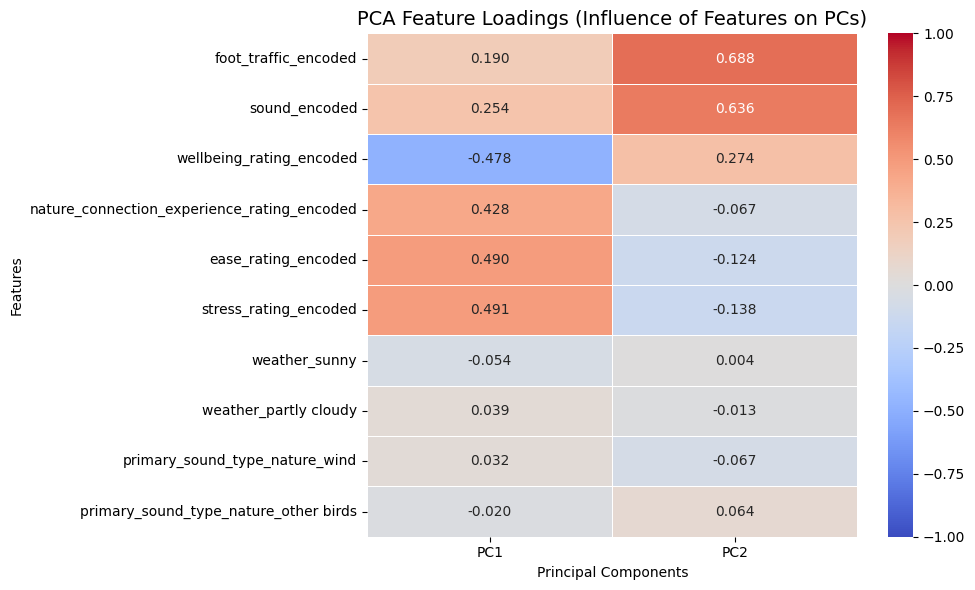

In [23]:
# Get the loadings (components_) for the 2-component PCA model we fitted earlier
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=cols_to_cluster
)

# Visualize the loadings using a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".3f",
    linewidths=0.5
)

plt.title('PCA Feature Loadings (Influence of Features on PCs)', fontsize=14)
plt.ylabel('Features')
plt.xlabel('Principal Components')
plt.tight_layout()
plt.show()

## **Interpreting data**

### **Cluster groupings**

* **Cluster 0:** *High foot traffic, lots of noise, very low wellbeing rating, decently high connection with nature, felt very stressed and very uneasy, the weather was sunny with a bit of clouds, main nature sound consisted of the wind and few birds.*

* **Cluster 1:** *Very low foot traffic, very quiet, very low wellbeing rating,much more connected to nature, slightly uneasy and stressed, sunny with clouds, lots of wind with very little bird sounds.*

* **Cluster 2:** *Really high foot traffic, moderate amounts of sound, neutral wellbeing rating, neutral nature connection experience, felt at easy and mostly calm, mostly sunny with little clouds, wind sounds with some bird sounds.*

* **Cluster 3:** *Low foot traffic, very quiet, very high wellbeing rating, very connected to nature, felt very at ease and very calm, very sunny and no clouds, the sound of wind is high and some birds making noise.*

* **Cluster 4:** *Low foot traffic, moderate amounts of sound, neutral wellbeing, neutral connection to nature, neutral for stress and ease, mildly cloudly and sunny, wind noise is prominent and few birds making noise.*



> We knew that the clusters were very close to being on the border of overlapping with each other due to the silhouette scores. But looking at the mean of each of the features makes it much more apparant.







In [24]:
df_cluster = df_cluster.copy()
df_cluster['cluster_label'] = labels

cluster_means = df_cluster.groupby('cluster_label').mean()
display(cluster_means)

,foot_traffic_encoded,sound_encoded,wellbeing_rating_encoded,nature_connection_experience_rating_encoded,ease_rating_encoded,stress_rating_encoded,weather_sunny,weather_partly cloudy,primary_sound_type_nature_wind,primary_sound_type_nature_other birds
cluster_label,,,,,,,,,,
0,1.192566,1.262362,-0.964209,0.744512,1.190527,1.267133,0.611111,0.277778,0.500000,0.277778
1,-0.587805,-0.611593,-1.071343,1.067843,0.704598,0.713031,0.560000,0.320000,0.760000,0.080000
2,1.402672,0.765555,0.427373,0.073989,-0.293670,-0.366040,0.652174,0.217391,0.521739,0.304348
3,-0.587805,-0.655666,1.063691,-1.211732,-1.052558,-0.960322,0.892857,0.035714,0.607143,0.214286
4,-0.513045,-0.151859,0.102873,-0.178876,-0.064054,-0.121051,0.431818,0.409091,0.500000,0.250000


### Questioning clustering / translating the cluster groupings

* Cluster 0 - Although people felt connected to nature, it was busy, loud and stressful, no one seems to have been comfortable. Could hear the wind and a few birds, sunny weather.

* Cluster 1 - Not a lot of noise or people around. Feeling very uncomfortable, uneasy, and stressed, but a much higher connection to nature. The sound of the wind was very dominant, sunny weather again.

* Cluster 2 - Lots of people, moderate amount of noise. Neutral comfort, didn't feel much closer to nature but felt calm and at ease. Wind sounds with some birds around, still sunny with a few clouds.

* Cluster 3 - People felt very happy, connected to nature, easy and calm. Seems to be deserted located with few people and sound. Very sunny weather with loud wind.

* Cluster 4 - Scarce amount of people, decent amount of sound, but people did not feel much here. They felt the same way as they usually do, the environment did not change their internal state. Fairly cloudly with sun, and wind sounds.

>  Cluster 0 & 1 seems to have had negative impacts on people, while cluster 3 had a very positive impact on people. Cluster 2 people felt calm and at easy but otherwise unchanged, while in cluster 4 people didn't feel much at all.

## **Reflection / limitations**

I learned quite a lot from this project, cleaning data, how to use different types of encoding and why, scaling data, finding the correlation between different features, clustering, PCA, and interpreting data.

There are things I tried that didn't work out, like using the label encoder from sklearning, because it was ordinal data and the function didn't sort them in order, this distorted the relationships between the features.

When I one-hot encoded the *[most_notable_nature_elements], [other_notes]* columns but they have too many unqiue pieces of data and make any kind of graph with it in it impossible to read, so I had to remove it.

Although I did encode nearly every single feature I only clustered 10, the reason being that I did a massive correlation with all the data I encoded and used a heat-map to pick out the features with the strongest relationships to make sure that they would form clusters.

I'd like to put the features I picked out through different algorithms and see what they produce rather than just being stuck to using one machine-learning model. Just because one algorithm might prove to be too simple or not fit for the data that it is running, although I don't thats the case here, I'm just curious to see if it'd be different.

I did run into some limitations while doing this. For the machine learning models, the more data and the more diverse it is the better. But because we collected the data and in fairly similar conditions, a lot of the data was the same and there wasn't a lot of it considering how much data machine learning models use these days.

Although I would say the biggest limitation, is being a beginner and having to do all this for the first time, which meant that there was a lot of trial and error. And realistically my inexperience leads to me making decisions and models that may not work the best for the type of data I'm working with.